In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
 import pandas as pd

data = {
    "StudyHours": [2, 3, 4, 5, 6, 7, 8, 9, 1, 3,
                    4, 5, 6, 7, 8, 2, 4, 6, 9, 10,
                    3, 5, 7, 8, 2, 6, 9, 4, 7, 10],

    "Attendance": [60, 65, 70, 75, 80, 85, 90, 95, 50, 55,
                   60, 70, 75, 80, 85, 90, 95, 65, 80, 98,
                   68, 72, 88, 92, 55, 78, 96, 62, 83, 99],

    "PreMarks": [40, 48, 52, 58, 65, 70, 78, 85, 30, 38,
                            45, 55, 60, 68, 75, 50, 65, 55, 82, 90,
                            48, 60, 72, 80, 35, 68, 88, 46, 70, 94],

    "Result": ["Fail", "Pass", "Pass", "Pass", "Pass",
               "Pass", "Pass", "Pass", "Fail", "Fail",
               "Fail", "Pass", "Pass", "Pass", "Pass",
               "Pass", "Pass", "Pass", "Pass", "Pass",
               "Pass", "Pass", "Pass", "Pass", "Fail",
               "Pass", "Pass", "Pass", "Pass", "Pass"]
}

df = pd.DataFrame(data)

print(df)

    StudyHours  Attendance  PreMarks Result
0            2          60        40   Fail
1            3          65        48   Pass
2            4          70        52   Pass
3            5          75        58   Pass
4            6          80        65   Pass
5            7          85        70   Pass
6            8          90        78   Pass
7            9          95        85   Pass
8            1          50        30   Fail
9            3          55        38   Fail
10           4          60        45   Fail
11           5          70        55   Pass
12           6          75        60   Pass
13           7          80        68   Pass
14           8          85        75   Pass
15           2          90        50   Pass
16           4          95        65   Pass
17           6          65        55   Pass
18           9          80        82   Pass
19          10          98        90   Pass
20           3          68        48   Pass
21           5          72      

In [ ]:
x = df[['StudyHours','Attendance','PreMarks']]
y = df['Result']

print('Input feature:')
display(x.head())
print('Output feature:')
display(y.head())

Input feature:


,StudyHours,Attendance,PreMarks
0,2,60,40
1,3,65,48
2,4,70,52
3,5,75,58
4,6,80,65


Output feature:


,Result
0,Fail
1,Pass
2,Pass
3,Pass
4,Pass


In [ ]:
x_tr, x_te, y_tr, y_te = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
    )

print("Training records:",len(x_tr))
print("Testing records:",len(x_te))

Training records: 24
Testing records: 6


In [ ]:
tree_clif = DecisionTreeClassifier(max_depth=4,random_state=42)
tree_clif.fit(x_tr,y_tr)

print("Decision Tree Model Trained Successfully")

Decision Tree Model Trained Successfully


In [ ]:
y_pred = tree_clif.predict(x_te)

comparison = pd.DataFrame({
    "Actual Result":y_te.values,
    "Predicted Result": y_pred
})

display(comparison)

,Actual Result,Predicted Result
0,Fail,Fail
1,Pass,Pass
2,Pass,Pass
3,Pass,Pass
4,Pass,Pass
5,Pass,Pass


In [ ]:
print("Accuracy:",round(accuracy_score(y_te,y_pred),2))
print("Classification Report:")
print(classification_report(y_te,y_pred))

Accuracy: 1.0
Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         5

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



[Text(0.5, 0.75, 'Attendance <= 61.0\ngini = 0.278\nsamples = 24\nvalue = [4, 20]\nclass = Pass'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]\nclass = Fail'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 20\nvalue = [0, 20]\nclass = Pass'),
 Text(0.625, 0.5, '  False')]

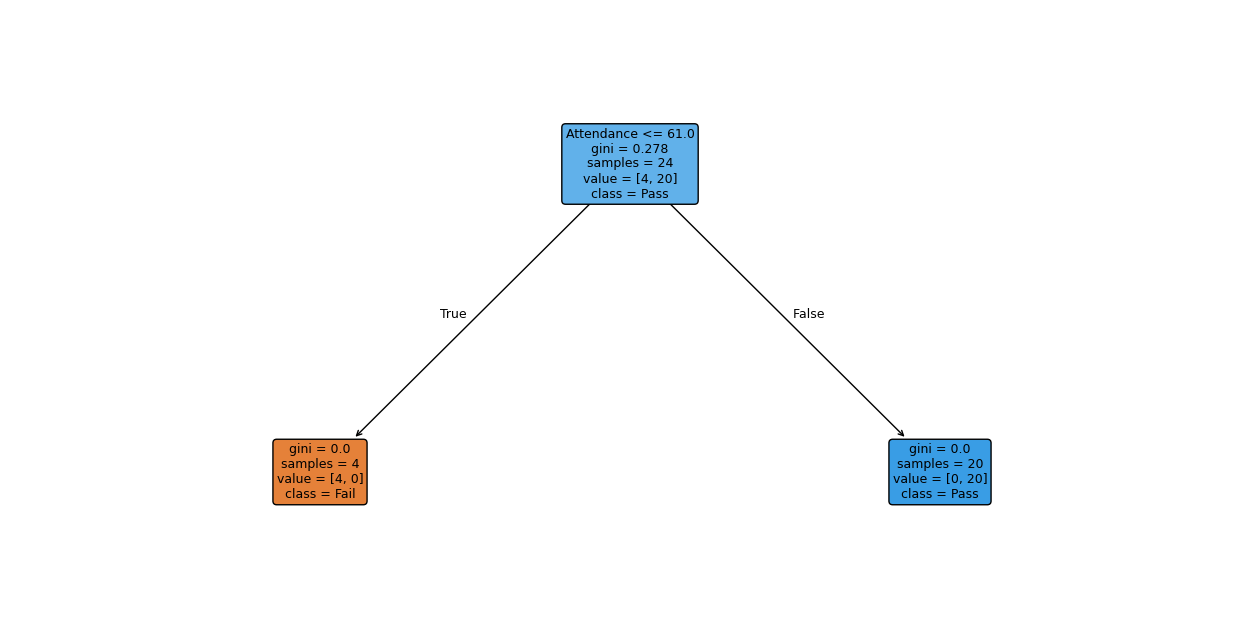

In [ ]:
plt.figure(figsize=(16,8))
plot_tree(
    tree_clif,
    feature_names=x.columns,
    class_names=["Fail","Pass"],
    filled=True,
    rounded=True,
    fontsize=9
)